# 0 — Data: where it comes from, what can be trusted, and the tables everything reads

**In brief**
- **Question:** Which NBA.com data can be trusted for its time, and what clean tables do the four segments read?
- **Answer:** Seven tables, all rebuilt here from an unchanged cache of NBA.com responses: one row per player-season (7,889, 2011-12 → 2025-26) and its playoff twin, the same with shrunk percentages and season-relative measures, each player's past trajectory, the position and star-score inputs, every player-game since 1999-00, and earlier All-Star selections. Several NBA.com sources look right but are not correct for their time; each is avoided.
- **Decisions** ([decision log](../docs/DECISIONS.md)): D1–D14.
- **Where it fits:** The foundation. Segments 1–4 read only the tables built here.
- **Dated:** written 13 November 2026, from notebooks 00–03 (now in [archive/](archive)), with the table builds of notebooks 04, 10 and 17. The detail and every intermediate check are in the archived notebooks.

**The rule behind everything:** an input for season *t* may use only seasons up to *t*.

## 0A — Sources, and the traps found

| Need | Source | Correct for its time? |
|---|---|---|
| Box-score and advanced statistics | `LeagueDashPlayerStats`, one call per season, as totals ([D1](../docs/DECISIONS.md)) | Yes |
| Height and weight | `LeagueDashPlayerBioStats`, per season ([D3](../docs/DECISIONS.md)) | Yes |
| Position, birth date | Each season's team rosters, `CommonTeamRoster` ([D4](../docs/DECISIONS.md), [D6](../docs/DECISIONS.md)) | Yes |
| Draft pick | `DraftHistory` | Yes |
| Every game | `LeagueGameLog`, 1999-00 onward | Yes |
| All-Star selections | Basketball-Reference names, then NBA.com awards by player ID ([D38](../docs/DECISIONS.md)) | Earlier selections only |

**Traps found along the way:**
- **`PlayerIndex` returns today's values for any season** (Jokić's current weight in 2018-19; LaMelo Ball listed before he entered the league). Never used.
- **Career totals include later seasons**, so they would leak the future. Never used.
- **The bio endpoint gives some players a wrong draft record** (Walker Russell Jr. gets his father's 1982 pick). Draft picks come from `DraftHistory`.
- **Undefined percentages come back as 0.0**, not missing (a 0-for-0 shooter shows 0%). Every percentage is recomputed from makes and attempts.
- **Same-name players** (Tim Hardaway and Tim Hardaway Jr.) are matched by player ID, never by name.
- **The NBA switched to measured heights in 2019-20**, so most players got shorter overnight. The cell below shows it from the cache.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nba_api.stats.endpoints import leaguedashplayerbiostats
from unicorn.plotting import BLUE, FIG_DIR, INK2, apply_style
from unicorn.raw import PROJECT_ROOT, fetch

warnings.filterwarnings("ignore")
apply_style()
PROCESSED = PROJECT_ROOT / "data" / "processed"

bio = {s: fetch(leaguedashplayerbiostats.LeagueDashPlayerBioStats, season=s, per_mode_simple="Totals")["LeagueDashPlayerBioStats"]
       for s in ["2018-19", "2019-20"]}
h = pd.concat([d.assign(season=s) for s, d in bio.items()]).pivot_table(index="PLAYER_ID", columns="season", values="PLAYER_HEIGHT_INCHES")
change = (h["2019-20"] - h["2018-19"]).dropna()
print(f"listed height, 2018-19 → 2019-20, same players (n = {len(change)}): shorter {(change < 0).mean():.0%}, "
      f"same {(change == 0).mean():.0%}, taller {(change > 0).mean():.0%}; mean change {change.mean():+.2f} inches")

listed height, 2018-19 → 2019-20, same players (n = 400): shorter 56%, same 39%, taller 5%; mean change -0.57 inches


## 0B — The raw cache

Every NBA.com response is stored unchanged (gzipped, with its parameters and the date fetched) in `data/raw/`, and every table is rebuilt from that cache. `python -m unicorn.download` fills it the first time (733 requests, resumable); after that, nothing is downloaded again.

In [2]:
from unicorn.download import download_all

log = download_all()          # instant when everything is cached
print(log["status"].str.split(":").str[0].value_counts().to_dict(), "| failed:", int(log["status"].str.startswith("FAILED").sum()))

{'cached': 733} | failed: 0


## 0C — One row per player-season, made comparable

`build_player_seasons` turns the cache into one row per player and season (2011-12 → 2025-26). Traded players get one combined row ([D1](../docs/DECISIONS.md)); no row is dropped, and minutes and attempts are kept so any threshold can be applied later ([D7](../docs/DECISIONS.md)); playoffs go in a separate table ([D8](../docs/DECISIONS.md)).

Two adjustments make the numbers fair to compare:
- **Shrinkage ([D11](../docs/DECISIONS.md)).** A player who makes 3 of 4 threes is not a 75% shooter. Each shooting percentage is pulled towards the typical rate for that season and position group, by an amount set by his attempts: the more attempts, the less it moves. Technically, a beta-binomial prior fitted by maximum likelihood for each season × position group, and the posterior mean.
- **Season-relative measures ([D12](../docs/DECISIONS.md)).** The league changed a lot (more threes, faster pace), so every measure is also expressed against that season's rotation players (500+ minutes), as a z-score and a percentile.

In [3]:
from unicorn.columns import relative_columns
from unicorn.features import SHRINK, season_relative, shrink_percentages
from unicorn.player_season import build_player_seasons

ps = build_player_seasons("Regular Season")
po = build_player_seasons("Playoffs")
feat = season_relative(shrink_percentages(ps), relative_columns())
checks = {
    "one row per player and season": not ps.duplicated(["player_id", "season"]).any(),
    "games started ≤ games played": bool((ps["gs"] <= ps["gp"]).all()),
    "makes ≤ attempts; threes ≤ all shots": bool(((ps["fgm"] <= ps["fga"]) & (ps["fg3a"] <= ps["fga"])).all()),
    "drafted no later than the season played": bool((ps["draft_year"].isna() | (ps["draft_year"] <= ps["season_start"])).all()),
}
print(f"player-seasons: {len(ps):,} × {ps.shape[1]} | playoffs: {len(po):,} | with shrinkage and season-relative measures: {feat.shape[1]} columns")
pd.Series(checks, name="passes")

player-seasons: 7,889 × 123 | playoffs: 3,230 | with shrinkage and season-relative measures: 200 columns


one row per player and season              True
games started ≤ games played               True
makes ≤ attempts; threes ≤ all shots       True
drafted no later than the season played    True
Name: passes, dtype: bool

In [4]:
# does shrinkage help? Predict next season's raw percentage from this season's raw or shrunk value.
# First training window only (2011-12 → 2015-16), so nothing later shapes the answer; errors weighted by next season's attempts.
nxt = feat[["player_id", "season_start", *SHRINK, "fg3a", "fta", "ra_fga", "fga"]].copy()
nxt["tsa"] = nxt["fga"] + 0.44 * nxt["fta"]
nxt["season_start"] -= 1
val = feat[feat["season_start"].between(2011, 2015)].merge(nxt, on=["player_id", "season_start"], suffixes=("", "_next"))
rows = []
for stat, w in {"fg3_pct": "fg3a_next", "ft_pct": "fta_next", "rim_fg_pct": "ra_fga_next", "ts_pct": "tsa"}.items():
    x = val[[stat, f"{stat}_shr", f"{stat}_next", w]].dropna()
    x = x[x[w] > 0]
    err = lambda c: np.average((x[c] - x[f"{stat}_next"]) ** 2, weights=x[w])
    rows.append({"percentage": stat, "player-seasons": len(x), "error cut by shrinkage": 1 - err(f"{stat}_shr") / err(stat)})
pd.DataFrame(rows).set_index("percentage").style.format({"error cut by shrinkage": "{:.0%}"})

,player-seasons,error cut by shrinkage
percentage,,
fg3_pct,1648,53%
ft_pct,1883,29%
rim_fg_pct,1894,43%
ts_pct,1932,32%


the same 35% three-point share: 69% percentile in 2011-12, 31% in 2025-26


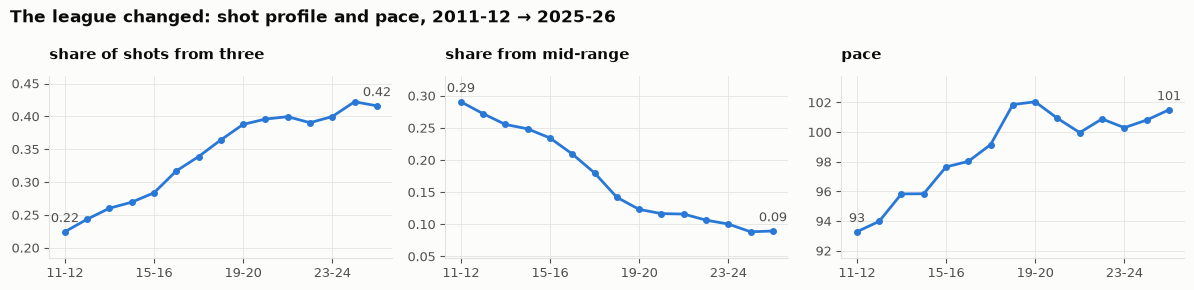

In [5]:
# why season-relative measures are needed: the league's shot profile, minutes-weighted
drift = {"fg3a_rate": "share of shots from three", "mid_rate": "share from mid-range", "pace": "pace"}
league = ps.groupby("season_start").apply(lambda g: pd.Series({c: np.average(g[c].dropna(), weights=g.loc[g[c].notna(), "min"]) for c in drift}),
                                          include_groups=False)
fig, axes = plt.subplots(1, 3, figsize=(12, 2.9), sharex=True)
for ax, (c, label) in zip(axes, drift.items()):
    ax.plot(league.index, league[c], color=BLUE, marker="o", markersize=4)
    ax.set_title(label, loc="left", pad=12); ax.margins(y=0.2)
    for i in (0, -1):
        v = league[c].iloc[i]
        ax.annotate(f"{v:.0f}" if c == "pace" else f"{v:.2f}", (league.index[i], v), xytext=(0, 7), textcoords="offset points", ha="center", color=INK2)
    ax.set_xticks([2011, 2015, 2019, 2023], ["11-12", "15-16", "19-20", "23-24"])
fig.suptitle("The league changed: shot profile and pace, 2011-12 → 2025-26", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "0_era_drift.png", dpi=150, bbox_inches="tight")
same = feat[feat["fg3a_rate"].between(0.345, 0.355) & (feat["min"] >= 500)].groupby("season_start")["fg3a_rate_pctl"].mean()
print(f"the same 35% three-point share: {same.iloc[0]:.0%} percentile in 2011-12, {same.iloc[-1]:.0%} in 2025-26")

## 0D — Each player's past, and the leakage test

For every measure, `add_trajectories` adds what the player's **past** seasons say: last season and the change since ([D13](../docs/DECISIONS.md): gaps for missed seasons are recorded, not skipped), the three-season level and trend, and how unusual this season is for him ([D14](../docs/DECISIONS.md)).

**The leakage test:** rebuild everything with every season after 2017-18 deleted. If any column used a later season, the earlier rows would change.

In [6]:
from unicorn.trajectories import add_trajectories

TRAJ_COLS = ["min"] + relative_columns() + [f"{c}_z" for c in relative_columns()]
traj = add_trajectories(feat, TRAJ_COLS)
cutoff = 2017
truncated = add_trajectories(feat[feat["season_start"] <= cutoff], TRAJ_COLS).set_index(["player_id", "season"]).sort_index()
full = traj[traj["season_start"] <= cutoff].set_index(["player_id", "season"]).sort_index()
new_cols = [c for c in truncated.columns if c not in feat.columns]
pd.testing.assert_frame_equal(full[new_cols], truncated[new_cols])
print(f"leakage test passed: all {len(new_cols)} trajectory columns are identical when every season after 2017-18 is deleted")

leakage test passed: all 349 trajectory columns are identical when every season after 2017-18 is deleted


## 0E — Position and the star score's inputs

The star score (segments 3 and 4 use it for "already clearly a star", [D42](../docs/DECISIONS.md)) is partly adjusted for body size, so it needs each player's **position spectrum**: where he sits from guard (1) to centre (5), by his listed position, his body and his style ([D5](../docs/DECISIONS.md), [D15](../docs/DECISIONS.md)). The same table carries the unicorn scores from the archived breakout work ([D16](../docs/DECISIONS.md)).

In [7]:
from unicorn.position import add_position_spectrum
from unicorn.unicorn import add_strangeness, add_unicorn_score

uni = add_strangeness(add_unicorn_score(add_position_spectrum(traj)))
print(f"{len(uni):,} player-seasons × {uni.shape[1]} columns; position spectrum for "
      f"{uni['position_style'].notna().mean():.0%} of player-seasons")

7,889 player-seasons × 558 columns; position spectrum for 100% of player-seasons


## 0F — Every game since 1999-00, and earlier All-Star selections

The Most Improved segments work from **game logs**, so they can stop a season at any day ([D22](../docs/DECISIONS.md) sets each player's baseline season). All-Star selections are looked up by player ID, and only **earlier** selections are ever used as an input ([D38](../docs/DECISIONS.md)).

In [8]:
from unicorn.allstars import allstar_selections
from unicorn.gamelogs import build_game_table, load_game_logs
from unicorn.mip_history import load_games

games, _, _ = build_game_table()                                   # 2010-11 → 2025-26, the table segments 1 and 4 read
history = load_games()                                             # 1999-00 → 2025-26, rebuilt from the cache whenever needed
live_logs = load_game_logs(["2026-27"]).rename(columns=str.lower)
players = pd.concat([history[["player_id", "player_name"]], live_logs[["player_id", "player_name"]]]).drop_duplicates("player_id")
sel, _ = allstar_selections(players)
print(f"player-games: {len(games):,} ({games['season'].min()} → {games['season'].max()}); "
      f"with the older seasons: {len(history):,} from {history['season'].min()}")
print(f"All-Star selections: {len(sel):,} for {sel['player_id'].nunique():,} players")

player-games: 404,431 (2010-11 → 2025-26); with the older seasons: 673,732 from 1999-00
All-Star selections: 900 for 220 players


## 0G — Save, and what each segment reads

Each table is compared with the copy already on disk before it is written, so a rebuild that changes anything says so.

In [9]:
def compare(old, new):
    """'identical', or the size of every difference: numeric columns by their largest change, others by rows that differ."""
    if list(old.columns) != list(new.columns) or len(old) != len(new):
        return f"different shape or columns: {old.shape} → {new.shape}"
    old, new = old.reset_index(drop=True), new.reset_index(drop=True)
    num, other = [], []
    for c in old.columns:
        a, b = old[c], new[c]
        if a.dtype.kind in "fi" and b.dtype.kind in "fi":
            d = (a.astype(float) - b.astype(float)).abs()
            if ((a.isna() != b.isna()) | (d > 0)).any():
                num.append((c, d.max()))
        elif (n := int((~((a == b) | (a.isna() & b.isna()))).sum())):   # values only: missing equals missing, storage type ignored
            other.append((c, n))
    if not num and not other:
        return "identical"
    parts = []
    if num:
        biggest = sorted(num, key=lambda t: -t[1])[:2]
        parts.append(f"{len(num)} numeric columns differ (largest: " + ", ".join(f"{c} {v:.2g}" for c, v in biggest) + ")")
    if other:
        parts.append(f"{len(other)} other columns differ (" + ", ".join(f"{c}: {n} rows" for c, n in other) + ")")
    return "; ".join(parts)

TABLES = {"player_season": (ps, "every segment"), "player_season_playoffs": (po, "archived breakout work"),
          "player_season_features": (feat, "0D"), "player_season_trajectories": (traj, "0E"),
          "player_season_unicorn": (uni, "the star score: segments 3 and 4"), "player_games": (games, "segments 1, 3 and 4"),
          "allstar_selections": (sel, "segments 3 and 4")}
rows = []
for name, (df, used) in TABLES.items():
    path = PROCESSED / f"{name}.parquet"
    status = compare(pd.read_parquet(path), df) if path.exists() else "new"
    df.to_parquet(path, index=False)
    rows.append({"table": name, "rows": len(df), "columns": df.shape[1], "read by": used, "against the copy on disk": status})
pd.DataFrame(rows).set_index("table").style.set_properties(**{"text-align": "left"})

,rows,columns,read by,against the copy on disk
table,,,,
player_season,7889,123,every segment,identical
player_season_playoffs,3230,107,archived breakout work,identical
player_season_features,7889,200,0D,"12 numeric columns differ (largest: fg3_pct_prior_n 1.7e+07, fg3_pct_shr_z 0.00079)"
player_season_trajectories,7889,549,0E,"52 numeric columns differ (largest: fg3_pct_prior_n 1.7e+07, fg3_pct_shr_z_delta 0.0008)"
player_season_unicorn,7889,558,the star score: segments 3 and 4,"58 numeric columns differ (largest: fg3_pct_prior_n 1.7e+07, strangeness_pctl 0.0055); 1 other columns differ (unicorn_pairs: 87 rows)"
player_games,404431,62,"segments 1, 3 and 4",identical
allstar_selections,900,2,segments 3 and 4,identical


## Findings (13 November 2026)

- **Four of the seven tables rebuild exactly; three differ by rounding, with no effect on any segment** (0G). The shrinkage prior is fitted by maximum likelihood, and for one group (bigs' three-point shooting in 2014-15) the likelihood keeps rising as the prior grows stronger, so the optimiser stops at an arbitrary point: 28 million attempts in the environment that first built it, 45 million now. Either way those players are shrunk fully to their group's average. Downstream, shrunk percentages move by at most 0.0008 standard deviations and the star score by 0.0000001; the star tier, every breakout label and the live model's inputs are unchanged. Only the archived unicorn analysis notices (87 unicorn-pair labels, 9 strangeness percentiles). The rebuilt tables are kept.
- **The live race's daily file is not rebuilt here:** it is a saved record, never recomputed.
- **Several NBA.com sources look right but are not correct for their time.** `PlayerIndex` returns today's values for any season, career totals include the future, and the bio endpoint has wrong draft records for some players. Each is avoided (0A).
- **The 2019-20 switch to measured heights** made most players shorter overnight (0A), so height is used as listed that season and compared within its season.
- **Shrinkage works:** it cuts next-season prediction error for every shooting percentage, most for three-point percentage (0C).
- **The league changed a lot** (the share of shots from three roughly doubled), so measures are compared within their season (0C).
- **The trajectory columns pass the leakage test:** deleting every later season changes nothing (0D).